<a href="https://colab.research.google.com/github/anaisrcast/Data-Science-Practice/blob/main/Practice/SalesData.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
print("Import Complete")

Import Complete


In [3]:
sales_df = pd.read_csv("messy_ecommerce_sales_data.csv")
sales_df.head(5)

,ID,Customer_Name,Order_ID,Order_Date,Product,Category,Quantity,Price,Payment_Method,Status,Total
0,100,Customer_100,ORD-41285,11/22/2024,Blender,Home,3,38,Cash on Delivery,Shipped,114.00
1,101,Customer_101,ORD-35783,7/5/2025,Smartphone,Electronics,2,abd,PayPal,Processing,NaN
2,102,Customer_102,ORD-84355,12/23/2024,Tennis Racket,Sports,1,389.05,PayPal,Delivered,389.05
3,103,Customer_103,ORD-57811,3/19/2025,Science,Books,5,233.92,PayPal,Processing,1169.60
4,104,Customer_104,ORD-93614,10/20/2025,Biography,Books,1,552.51,Cash on Delivery,Processing,552.51


In [4]:
sales_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 103 entries, 0 to 102
Data columns (total 11 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   ID              103 non-null    int64  
 1    Customer_Name  103 non-null    object 
 2   Order_ID        103 non-null    object 
 3   Order_Date      103 non-null    object 
 4   Product         103 non-null    object 
 5    Category       95 non-null     object 
 6   Quantity        98 non-null     object 
 7   Price           98 non-null     object 
 8   Payment_Method  103 non-null    object 
 9   Status          103 non-null    object 
 10  Total           89 non-null     float64
dtypes: float64(1), int64(1), object(9)
memory usage: 9.0+ KB


---
#NEXT STEPS:
- Column names have additional spaces in the naming convention
- There a number of nulls rows within 'Category', 'Quantity', 'Price', 'Total'
- Data types for 'Order_Date', 'Quanity'and 'Price' need to updated accordingly

In [5]:
#strip the column headers
sales_df.columns = sales_df.columns.str.strip()

#Correct data types
#------------
#Date
sales_df['Order_Date'] = pd.to_datetime(sales_df['Order_Date'], format='mixed',errors='coerce')
#Float Price
sales_df['Price'] = pd.to_numeric(sales_df['Price'], errors = "coerce")
#Interger Quantity
sales_df['Quantity'] = pd.to_numeric(sales_df['Quantity'], errors = "coerce")

#+ rows with make them all the same case
if sales_df['Category'].dtype == 'object':
    sales_df['Category'] = sales_df['Category'].str.lower()

In [6]:
sales_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 103 entries, 0 to 102
Data columns (total 11 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   ID              103 non-null    int64         
 1   Customer_Name   103 non-null    object        
 2   Order_ID        103 non-null    object        
 3   Order_Date      102 non-null    datetime64[ns]
 4   Product         103 non-null    object        
 5   Category        95 non-null     object        
 6   Quantity        97 non-null     float64       
 7   Price           94 non-null     float64       
 8   Payment_Method  103 non-null    object        
 9   Status          103 non-null    object        
 10  Total           89 non-null     float64       
dtypes: datetime64[ns](1), float64(3), int64(1), object(6)
memory usage: 9.0+ KB


Notes: Additional nulls have appeared once the data types were updated
---
# Next Steps:
- Investigate null rows to see if it is possible to replace or remove

In [7]:
sales_df[sales_df['Order_Date'].isnull()]

,ID,Customer_Name,Order_ID,Order_Date,Product,Category,Quantity,Price,Payment_Method,Status,Total
92,192,Customer_192,ORD-35144,NaT,Jacket,clothing,NaN,203.63,Credit Card,Returned,NaN


Delete null in 'Order_Date' column since it is only one row and the Order_date, Quantity and Total is missing

In [8]:
sales_df = sales_df.dropna(subset = ['Order_Date'])
sales_df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 102 entries, 0 to 102
Data columns (total 11 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   ID              102 non-null    int64         
 1   Customer_Name   102 non-null    object        
 2   Order_ID        102 non-null    object        
 3   Order_Date      102 non-null    datetime64[ns]
 4   Product         102 non-null    object        
 5   Category        94 non-null     object        
 6   Quantity        97 non-null     float64       
 7   Price           93 non-null     float64       
 8   Payment_Method  102 non-null    object        
 9   Status          102 non-null    object        
 10  Total           89 non-null     float64       
dtypes: datetime64[ns](1), float64(3), int64(1), object(6)
memory usage: 9.6+ KB


Will investigate nulls in the 'Category' column

In [9]:
sales_df[sales_df['Category'].isnull()]

,ID,Customer_Name,Order_ID,Order_Date,Product,Category,Quantity,Price,Payment_Method,Status,Total
33,133,Customer_133,ORD-68182,2024-12-05,Biography,NaN,5.0,343.24,Credit Card,Shipped,1716.20
36,136,Customer_136,ORD-20985,2025-06-12,Headphones,NaN,1.0,696.71,Credit Card,Delivered,696.71
80,180,Customer_180,ORD-86629,2025-03-26,Laptop,NaN,2.0,418.38,Credit Card,Processing,836.76
81,181,Customer_181,ORD-54481,2024-12-29,Smartphone,NaN,1.0,266.48,Cash on Delivery,Cancelled,266.48
82,182,Customer_182,ORD-79672,2025-08-03,Shoes,NaN,4.0,538.35,PayPal,Processing,2153.40
84,184,Customer_184,ORD-67799,2025-02-15,Jeans,NaN,4.0,101.19,Bank Transfer,Processing,404.76
93,193,Customer_193,ORD-42475,2025-06-06,Basketball,NaN,NaN,522.02,PayPal,Shipped,NaN
98,198,Customer_198,ORD-14608,2025-07-27,Vacuum,NaN,2.0,497.01,Cash on Delivery,Shipped,994.02


# Want to create a dimension table to match up the different products and category

Will use the dimenstion table to fill in the nulls within the original dataset if there is a match OR no repeats

In [10]:
#Grabbing the Products for the Categories that are null to use later...
Product_Nulls = sales_df[sales_df['Category'].isnull()]['Product'].unique()
print(Product_Nulls)

['Biography' 'Headphones' 'Laptop' 'Smartphone' 'Shoes' 'Jeans'
 'Basketball' 'Vacuum']


In [11]:
#Creating the dimension table with Products and Categories
prod_cat_df = sales_df[['Product', 'Category']].dropna()
prod_cat_df = prod_cat_df.drop_duplicates()
prod_cat_df = prod_cat_df.sort_values(['Product', 'Category'])

In [12]:
prod_cat_df[prod_cat_df['Product'].isin(Product_Nulls)]

,Product,Category
46,Basketball,electronic
10,Basketball,sports
4,Biography,books
75,Headphones,electronics
56,Jeans,clothing
45,Laptop,electronics
12,Shoes,clothing
1,Smartphone,electronics
23,Vacuum,electronic
37,Vacuum,home


**Can** fill in the products for Headphones, Jeans, Laptop, Shoes, Smartphone

I hesitate to fill in 'Basketball' Product since there are 2 different categories and the Kaggle description does not clarify the different categories. Can see this fit into NBA 2k (electronic) and a basketball (sports). Will drop the rows with the 'Basketball' Product with null Categories since there is no clear direction.

Will combine the Vacuum products to consolidate into one category, arbitrarily chose 'home' since there is not direction in the kaggle dataset

In [13]:
#change vacuum to the same category
sales_df.loc[sales_df['Product'] == 'Vacuum', 'Category'] = 'home'
#recreate dimension table
prod_cat_df = sales_df[['Product', 'Category']].dropna()
prod_cat_df = prod_cat_df.drop_duplicates()
prod_cat_df = prod_cat_df.sort_values(['Product', 'Category'])
#drop basketball products
prod_cat_df = prod_cat_df.loc[prod_cat_df['Product'] != 'Basketball']
#View new dimension table
prod_cat_df[prod_cat_df['Product'].isin(Product_Nulls)]

,Product,Category
4,Biography,books
75,Headphones,electronics
56,Jeans,clothing
45,Laptop,electronics
12,Shoes,clothing
1,Smartphone,electronics
23,Vacuum,home


In [14]:
#Lookup the nulls in the new dimension table!
cat_lookup = prod_cat_df.set_index('Product').to_dict()['Category']
sales_df['Category'] = sales_df['Category'].fillna(sales_df['Product'].map(cat_lookup))
#drop nas in Category column
sales_df = sales_df.dropna(subset = ['Category'])
sales_df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 101 entries, 0 to 102
Data columns (total 11 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   ID              101 non-null    int64         
 1   Customer_Name   101 non-null    object        
 2   Order_ID        101 non-null    object        
 3   Order_Date      101 non-null    datetime64[ns]
 4   Product         101 non-null    object        
 5   Category        101 non-null    object        
 6   Quantity        97 non-null     float64       
 7   Price           92 non-null     float64       
 8   Payment_Method  101 non-null    object        
 9   Status          101 non-null    object        
 10  Total           89 non-null     float64       
dtypes: datetime64[ns](1), float64(3), int64(1), object(6)
memory usage: 9.5+ KB


In [15]:
#double checking it filled in correctly
sales_df[sales_df['Customer_Name'] == 'Customer_198']

,ID,Customer_Name,Order_ID,Order_Date,Product,Category,Quantity,Price,Payment_Method,Status,Total
98,198,Customer_198,ORD-14608,2025-07-27,Vacuum,home,2.0,497.01,Cash on Delivery,Shipped,994.02


Will now look at the nulls in the 'Quantity' column

In [16]:
sales_df[sales_df['Quantity'].isnull()]

,ID,Customer_Name,Order_ID,Order_Date,Product,Category,Quantity,Price,Payment_Method,Status,Total
6,106,Customer_106,ORD-25885,2025-02-02,Blender,home,NaN,978.63,Bank Transfer,Processing,NaN
64,164,Customer_164,ORD-23010,2025-02-09,Tennis Racket,sports,NaN,587.64,Credit Card,Returned,NaN
67,167,Customer_167,ORD-30329,2025-08-07,Basketball,sports,NaN,593.93,Cash on Delivery,Processing,NaN
96,196,Customer_196,ORD-78384,2024-12-23,Vacuum,home,NaN,NaN,PayPal,Delivered,NaN


In [17]:
#Fill in the Qunatities based on Product, Category duo + round to the nearest whole number
sales_df['Quantity'] = sales_df['Quantity'].fillna(
    sales_df.groupby(['Product', 'Category'])['Quantity'].transform('mean').round(0)
)
#double check everything filled in correctly
sales_df[sales_df['Customer_Name'] == 'Customer_106']

,ID,Customer_Name,Order_ID,Order_Date,Product,Category,Quantity,Price,Payment_Method,Status,Total
6,106,Customer_106,ORD-25885,2025-02-02,Blender,home,4.0,978.63,Bank Transfer,Processing,NaN


Will now look at the Null rows in the 'Price' Column

In [18]:
sales_df[sales_df['Price'].isnull()]

,ID,Customer_Name,Order_ID,Order_Date,Product,Category,Quantity,Price,Payment_Method,Status,Total
1,101,Customer_101,ORD-35783,2025-07-05,Smartphone,electronics,2.0,NaN,PayPal,Processing,NaN
10,110,Customer_110,ORD-61020,2025-09-26,Basketball,sports,5.0,NaN,Cash on Delivery,Cancelled,NaN
16,116,Customer_116,ORD-63660,2025-10-30,Microwave,home,4.0,NaN,Cash on Delivery,Processing,NaN
20,120,Customer_120,ORD-14659,2025-06-13,Yoga Mat,electronics,5.0,NaN,Credit Card,Cancelled,NaN
24,124,Customer_124,ORD-46136,2025-05-31,Comics,books,5.0,NaN,PayPal,Cancelled,NaN
30,130,Customer_130,ORD-34007,2025-08-15,Tennis Racket,sports,2.0,NaN,Bank Transfer,Processing,NaN
56,156,Customer_156,ORD-34679,2024-11-28,Jeans,clothing,2.0,NaN,Bank Transfer,Shipped,NaN
83,183,Customer_183,ORD-20916,2025-03-10,Shoes,clothing,5.0,NaN,Cash on Delivery,Returned,NaN
96,196,Customer_196,ORD-78384,2024-12-23,Vacuum,home,2.0,NaN,PayPal,Delivered,NaN


In [19]:
sales_df['Price'] = sales_df['Price'].fillna(
    sales_df.groupby(['Product', 'Category'])['Price'].transform('mean').round(2)
)
#double check everything filled in correctly
sales_df[sales_df['Customer_Name'] == 'Customer_101']

,ID,Customer_Name,Order_ID,Order_Date,Product,Category,Quantity,Price,Payment_Method,Status,Total
1,101,Customer_101,ORD-35783,2025-07-05,Smartphone,electronics,2.0,560.99,PayPal,Processing,NaN


Will look at the Total column for nulls

In [20]:
sales_df[sales_df['Total'].isnull()]

,ID,Customer_Name,Order_ID,Order_Date,Product,Category,Quantity,Price,Payment_Method,Status,Total
1,101,Customer_101,ORD-35783,2025-07-05,Smartphone,electronics,2.0,560.99,PayPal,Processing,NaN
6,106,Customer_106,ORD-25885,2025-02-02,Blender,home,4.0,978.63,Bank Transfer,Processing,NaN
10,110,Customer_110,ORD-61020,2025-09-26,Basketball,sports,5.0,534.32,Cash on Delivery,Cancelled,NaN
16,116,Customer_116,ORD-63660,2025-10-30,Microwave,home,4.0,408.05,Cash on Delivery,Processing,NaN
20,120,Customer_120,ORD-14659,2025-06-13,Yoga Mat,electronics,5.0,266.70,Credit Card,Cancelled,NaN
24,124,Customer_124,ORD-46136,2025-05-31,Comics,books,5.0,743.05,PayPal,Cancelled,NaN
30,130,Customer_130,ORD-34007,2025-08-15,Tennis Racket,sports,2.0,400.04,Bank Transfer,Processing,NaN
56,156,Customer_156,ORD-34679,2024-11-28,Jeans,clothing,2.0,421.41,Bank Transfer,Shipped,NaN
64,164,Customer_164,ORD-23010,2025-02-09,Tennis Racket,sports,2.0,587.64,Credit Card,Returned,NaN
67,167,Customer_167,ORD-30329,2025-08-07,Basketball,sports,4.0,593.93,Cash on Delivery,Processing,NaN


In [21]:
sales_df['Total'] = sales_df['Total'].fillna(
    sales_df['Quantity'] * sales_df['Price']
)
#double check everything filled in correctly
sales_df[sales_df['Customer_Name'] == 'Customer_101']

,ID,Customer_Name,Order_ID,Order_Date,Product,Category,Quantity,Price,Payment_Method,Status,Total
1,101,Customer_101,ORD-35783,2025-07-05,Smartphone,electronics,2.0,560.99,PayPal,Processing,1121.98


In [22]:
#double check there is NO more nulls to clean
sales_df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 101 entries, 0 to 102
Data columns (total 11 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   ID              101 non-null    int64         
 1   Customer_Name   101 non-null    object        
 2   Order_ID        101 non-null    object        
 3   Order_Date      101 non-null    datetime64[ns]
 4   Product         101 non-null    object        
 5   Category        101 non-null    object        
 6   Quantity        101 non-null    float64       
 7   Price           101 non-null    float64       
 8   Payment_Method  101 non-null    object        
 9   Status          101 non-null    object        
 10  Total           101 non-null    float64       
dtypes: datetime64[ns](1), float64(3), int64(1), object(6)
memory usage: 9.5+ KB


<Axes: xlabel='Category'>

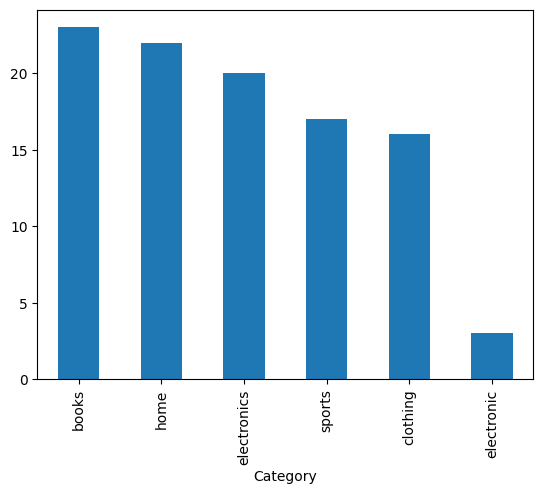

In [23]:
# Bar graph count of different categories - noticed something!
sales_df['Category'].value_counts().plot(kind='bar')

## More cleaning identified!

Electronic**s** > Electronic

In [24]:
# Change 'electronics' category to 'electorinic' to
sales_df['Category'] = sales_df['Category'].replace('electronics', 'electronic')
sales_df['Category'].unique()

array(['home', 'electronic', 'sports', 'books', 'clothing'], dtype=object)

# Clean is complete!

---

#Next step:
- Analysis

<Axes: xlabel='Category'>

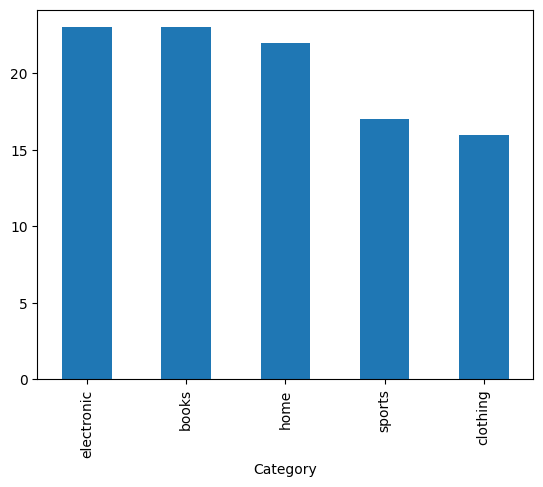

In [25]:
sales_df['Category'].value_counts().plot(kind='bar')

## How many products does each 'Category' have?


In [26]:
sales_df.groupby('Category')['Product'].nunique()

,Product
Category,
books,4
clothing,5
electronic,10
home,4
sports,4


Which 'Category' brings in the most revenue?

<Axes: xlabel='Category'>

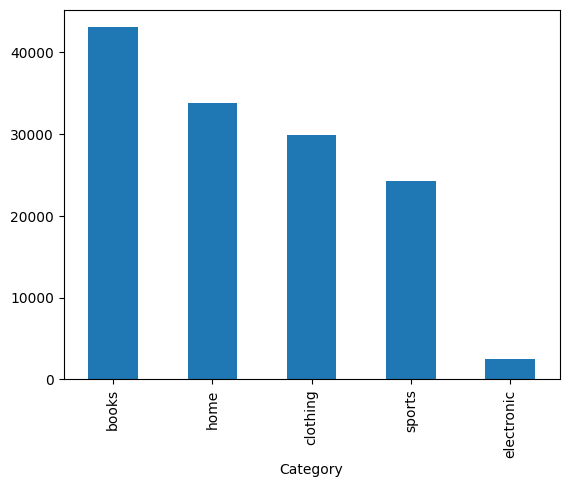

In [27]:
(sales_df.groupby('Category')['Total'].sum().round(2)).sort_values(ascending = False).plot(kind = 'bar')

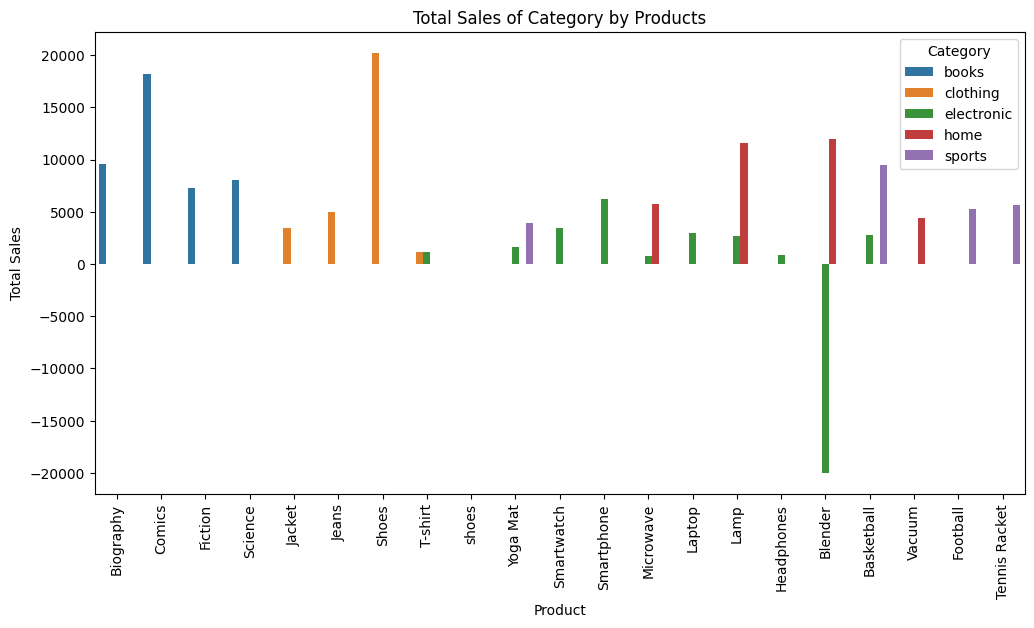

In [28]:
#More granual look at different products within the category
Rev_prod = (sales_df.groupby(['Category','Product'], as_index= False)['Total']
            .sum()
            .round(2)
            .sort_values(['Category']))

#plot using MatPlot + Seaborn package
plt.figure(figsize=(12, 6))
sns.barplot(data = Rev_prod, x= 'Product', y = 'Total', hue = 'Category')
#Additional Details for graph
plt.title('Total Sales of Category by Products')
plt.xlabel('Product')
plt.ylabel('Total Sales')
plt.xticks(rotation = 90)
plt.show()

# Next Steps:

## Based on the current graph there are a couple things that pop out to me as odd/ need to be fixed



1.   Certain 'Products' are in multiple categories:

*   T-shirt: 'clothing' AND 'electronic'
*   Yoga Mat: 'sports' and 'electronic'
*   Microwave: 'electronic' AND 'home'
*   Lamp: 'home' and 'electronic'
*   Blender: 'home' and 'electronic'
*   Basketball: 'sports' and 'home' - *decided to keep this the same due to preiovus reasoning*

2.   Why does Blender have such a high negative balance???



In [29]:
# Next steps with multiple categories.... would you like to split it out or decide on a category to consolidate?

# T-shirt : 'clothing' Category
sales_df.loc[sales_df['Product'] == 'T-shirt', 'Category'] = 'clothing'

# Yoga Mat : 'sports' Category
sales_df.loc[sales_df['Product'] == 'Yoga Mat', 'Category'] = 'sports'


# Microwave : 'home' Category
sales_df.loc[sales_df['Product'] == 'Microwave', 'Category'] = 'home'

# Lamp : 'home' category
sales_df.loc[sales_df['Product'] == 'Lamp', 'Category'] = 'home'

# Blender : 'home' category
sales_df.loc[sales_df['Product'] == 'Blender', 'Category'] = 'home'


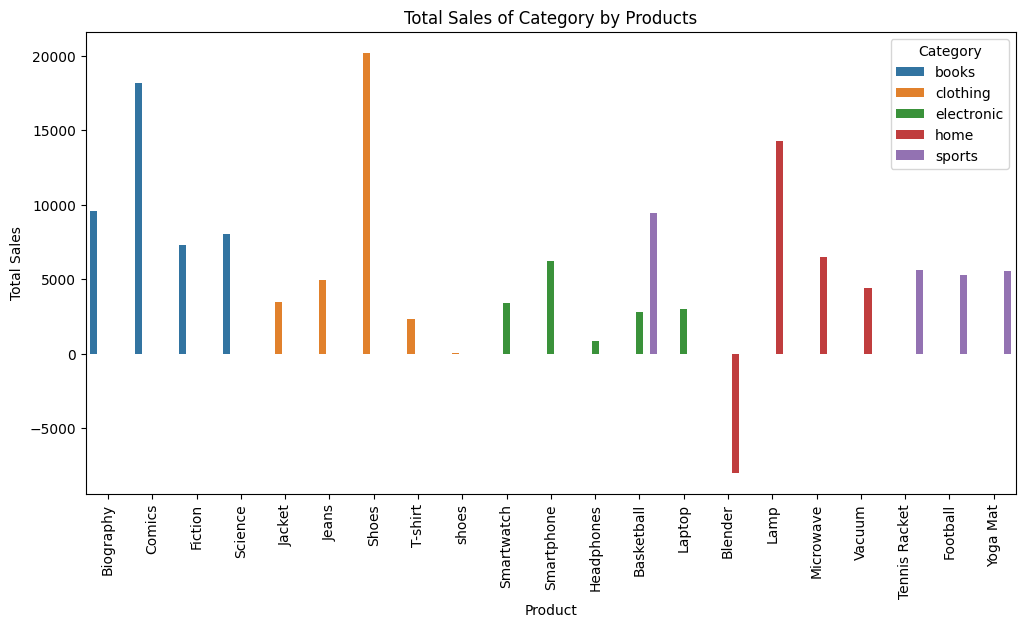

In [30]:
#Let's relook at the graph real quick
Rev_prod = (sales_df.groupby(['Category','Product'], as_index= False)['Total']
            .sum()
            .round(2)
            .sort_values(['Category']))

#plot using MatPlot + Seaborn package
plt.figure(figsize=(12, 6))
sns.barplot(data = Rev_prod, x= 'Product', y = 'Total', hue = 'Category')
#Additional Details for graph
plt.title('Total Sales of Category by Products')
plt.xlabel('Product')
plt.ylabel('Total Sales')
plt.xticks(rotation = 90)
plt.show()

## Now onto the Blender Problem

In [31]:
#Look at the sales for Blenders, why is there a high credit?
sales_df[sales_df['Product'] == 'Blender']

,ID,Customer_Name,Order_ID,Order_Date,Product,Category,Quantity,Price,Payment_Method,Status,Total
0,100,Customer_100,ORD-41285,2024-11-22,Blender,home,3.0,38.00,Cash on Delivery,Shipped,114.00
6,106,Customer_106,ORD-25885,2025-02-02,Blender,home,4.0,978.63,Bank Transfer,Processing,3914.52
17,117,Customer_117,ORD-72751,2025-02-12,Blender,home,-2.0,10000.00,Cash on Delivery,Processing,-20000.00
27,127,Customer_127,ORD-65482,2025-05-12,Blender,home,5.0,336.02,Bank Transfer,Returned,1680.10
54,154,Customer_154,ORD-95990,2025-02-21,Blender,home,5.0,789.64,Cash on Delivery,Cancelled,3948.20
62,162,Customer_162,ORD-27743,2025-05-19,Blender,home,2.0,155.76,Credit Card,Returned,311.52
97,197,Customer_197,ORD-79139,2025-06-23,Blender,home,1.0,160.16,PayPal,Cancelled,160.16
99,199,Customer_199,ORD-82922,2025-01-22,Blender,home,5.0,372.28,Credit Card,Shipped,1861.40


In [32]:
#This is either a case of money laundering ! or we have some data outliers

#Let us see if having a negative total is normal
sales_df[sales_df['Total'] < 0]

,ID,Customer_Name,Order_ID,Order_Date,Product,Category,Quantity,Price,Payment_Method,Status,Total
17,117,Customer_117,ORD-72751,2025-02-12,Blender,home,-2.0,10000.00,Cash on Delivery,Processing,-20000.00
34,134,Customer_134,ORD-16585,2025-10-04,T-shirt,clothing,-5.0,591.53,PayPal,Shipped,-2957.65
37,137,Customer_137,ORD-91254,2025-02-23,Vacuum,home,3.0,-100.00,Cash on Delivery,Delivered,-300.00


In [33]:
#NOT normal!!

#Let's see if quantities are normally negative, let me take a closer look at that as well
sales_df[sales_df['Quantity'] < 0]

,ID,Customer_Name,Order_ID,Order_Date,Product,Category,Quantity,Price,Payment_Method,Status,Total
17,117,Customer_117,ORD-72751,2025-02-12,Blender,home,-2.0,10000.00,Cash on Delivery,Processing,-20000.00
34,134,Customer_134,ORD-16585,2025-10-04,T-shirt,clothing,-5.0,591.53,PayPal,Shipped,-2957.65


In [34]:
# I am deciding to drop those 3 values in total, since they seem to be outliers in the dataset
sales_df = sales_df[sales_df['Total'] > 0]

#double check if the values are still in the dataset
sales_df[sales_df['Total'] < 0]

,ID,Customer_Name,Order_ID,Order_Date,Product,Category,Quantity,Price,Payment_Method,Status,Total


## Now that we have the outliers removed there SHOULD be columns that are zero, such as...

In [35]:
sales_df['Status'].unique()

array(['Shipped', 'Processing', 'Delivered', 'Cancelled', 'Returned'],
      dtype=object)

## Cancelled = 0

Cancelled invoices are probably money we will never receive, since the dataset does not seem to have repeat order_id or customer_name, I assume this/ the dataset only has the most recent status of the invoice, not multiple entries

## Returned = 0

Returned invoices are probably money we had to refund back because the customer was not satisfied, this would typically be negative but since this is the most recent status of the invoice the charge will cancel out.

In [36]:
# Cancelled
sales_df.loc[sales_df['Status'] == 'Cancelled', 'Total'] = 0

# Yoga Mat : 'sports' Category
sales_df.loc[sales_df['Status'] == 'Returned', 'Total'] = 0

print(sales_df[sales_df['Status'] == 'Cancelled'].head(5))

print(sales_df[sales_df['Status'] == 'Returned'].head(5))

     ID Customer_Name   Order_ID Order_Date        Product Category  Quantity  \
5   105  Customer_105  ORD-22442 2024-11-20  Tennis Racket   sports       3.0   
10  110  Customer_110  ORD-61020 2025-09-26     Basketball   sports       5.0   
20  120  Customer_120  ORD-14659 2025-06-13       Yoga Mat   sports       5.0   
23  123  Customer_123  ORD-11314 2025-10-06         Vacuum     home       3.0   
24  124  Customer_124  ORD-46136 2025-05-31         Comics    books       5.0   

     Price    Payment_Method     Status  Total  
5   122.06  Cash on Delivery  Cancelled    0.0  
10  534.32  Cash on Delivery  Cancelled    0.0  
20  266.70       Credit Card  Cancelled    0.0  
23  615.91  Cash on Delivery  Cancelled    0.0  
24  743.05            PayPal  Cancelled    0.0  
     ID Customer_Name   Order_ID Order_Date    Product Category  Quantity  \
7   107  Customer_107  ORD-89122 2025-01-03  Biography    books       5.0   
11  111  Customer_111  ORD-72349 2025-10-22     Comics    books  

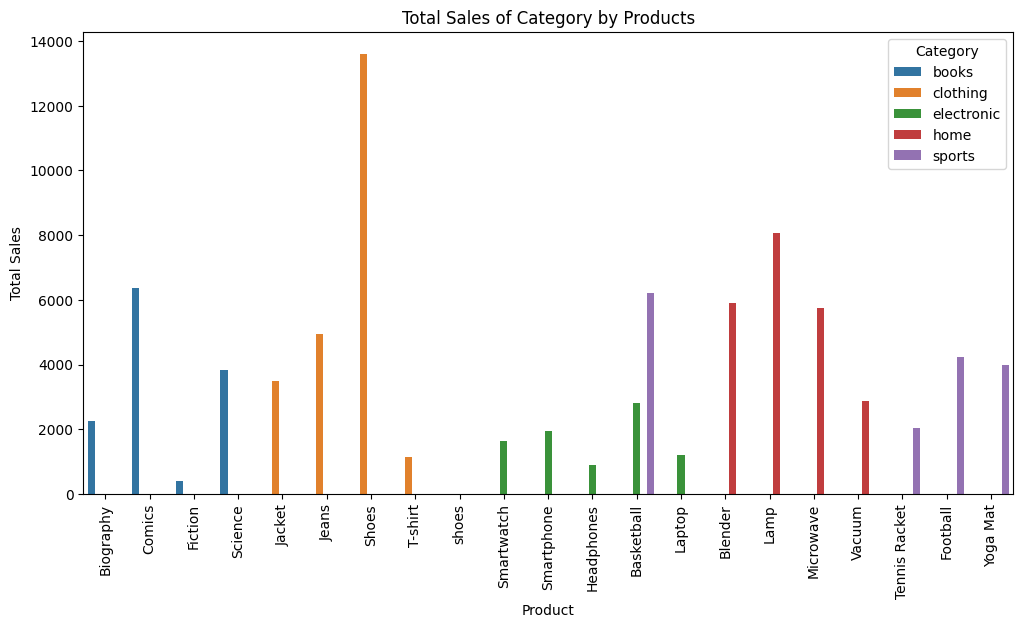

In [37]:
#The graph represents the true sum for products!
Rev_prod = (sales_df.groupby(['Category','Product'], as_index= False)['Total']
            .sum()
            .round(2)
            .sort_values(['Category']))

#plot using MatPlot + Seaborn package
plt.figure(figsize=(12, 6))
sns.barplot(data = Rev_prod, x= 'Product', y = 'Total', hue = 'Category')
#Additional Details for graph
plt.title('Total Sales of Category by Products')
plt.xlabel('Product')
plt.ylabel('Total Sales')
plt.xticks(rotation = 90)
plt.show()

## Current thoughts based on findings:

* Create a graph to look at the break out count for each 'status', 'payment_method' compared to category and product

* Which product tends to be ordered the most in one order? ('Quantity')

* 'Shoes' product is pretty high now after all the adjustments, why?


<Axes: xlabel='Payment_Method'>

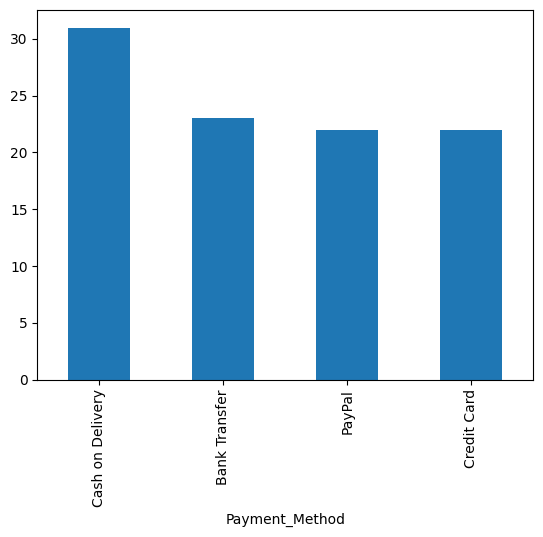

In [43]:
#Visualize the distribution of payment methods used

sales_df['Payment_Method'].value_counts().plot(kind='bar')

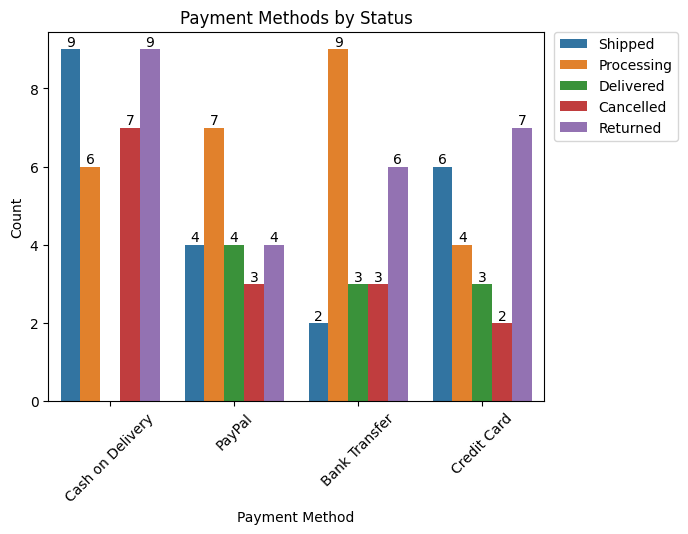

In [57]:
# The breakout of 'payment methods' and 'status' columns
ps = sns.countplot(data = sales_df, x = 'Payment_Method', hue = 'Status')
#provide a way to display the counts for each bar
for cont in ps.containers:
  ps.bar_label(cont)

#Provide proper labels for the count plot
plt.title('Payment Methods by Status')
plt.xlabel('Payment Method')
plt.ylabel('Count')
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left', borderaxespad=0) #displays the legend outside of the graph
plt.xticks(rotation = 45)
plt.show()


#Visualization: Payment Method grouped by Status - bar graph
## Based on the graph it seems to reveal that some payment methods have trends (?) in their status.
- It seems that all Cash deliveries have never been sucessfully delivered, along with this stat, it seems that they contain the most amount of returns and cancelled invoices. It could be a wise business deciosion, as a company, to reconsider this option of payment.

- While no payment method paticularly stood out as the 'best' performing payment method. I would like to note that Credit Card payments was able to see the highest sucessful deliveries. On that same note, PayPal payments had the least amount of returns.

---
# Conclusion:

Although this data was relatively small, when it comes to sales, this dataset offered an opportunity to practice cleaning on a dataset. However, while trying to perform analysis the limited dataset it became difficult to properly analyze meaningful trends. I have left a few questions unanswered due to the lack of data available. In the future I would like to work on a larger dataset that would allow for more in depth analysis of sales performance.